In [ ]:
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
from functions_library import *

In [ ]:
from iminuit import Minuit
notebook_dir = Path.cwd()
data_dir = notebook_dir.parent.parent / "csv_files"
data_egam1 = np.loadtxt(data_dir / "Z_mass_EGAM1.csv", delimiter=",")
data_egam7 = np.loadtxt(data_dir / "Z_mass_EGAM7.csv", delimiter=",")
data_egamD = np.loadtxt(data_dir / "Z_mass_DataEgamma.csv", delimiter=",")
#data_muon1 = np.loadtxt(data_dir / "Z_mass_MUON1.csv", delimiter=",")
#data_muonD = np.loadtxt(data_dir / "Z_mass_DataMuon.csv", delimiter=",")


In [ ]:
def data_fit_ratio(x, ratio):
    return (
        ratio * curve_fitting.breit_wigner_crystal_ball(x, *vals_egam1)
        + (1 - ratio) * curve_fitting.exponential_decay(x, *vals_egam7)
    )

bw_cb_limits = [
    (0.1, 10.0),
    (60.0, 120.0),
    (2.0, 4.0),
    (0.5, 10.0),
    (0.0, 4.0),
    (0.0, 20.0),
]

exp_limits = [
    (0.01, 10.0),
    (0.01, 10.0),
]

ratio_limits = [
    (1e-6, 1.0),
]

data_fit_limits = [
    (0.1, 10.0),
    (0.1, 10.0),
    (60.0, 120.0),
    (2.0, 4.0),
    (0.5, 10.0),
    (0.0, 4.0),
    (0.0, 20.0),
    (0.01, 10.0),
]

In [ ]:
bins = np.arange(55.05, 135.05, 0.1)
vals_egam1 = curve_fitting.fit_function(
    data_egam1 / 1000,
    bins,
    curve_fitting.breit_wigner_crystal_ball,
    initial_guess=[1.09716406, 91.1876, 2.98179821, 1.91401491, 1.16373524, 1.86966453],
    limits=bw_cb_limits,
)

vals_egam7 = curve_fitting.fit_function(
    data_egam7 / 1000,
    bins,
    curve_fitting.exponential_decay,
    initial_guess=[1, 0.1],
    limits=exp_limits,
)

#vals_egamD_ratio = curve_fitting.fit_function(
#    data_egamD / 1000,
#    bins,
#    data_fit_ratio,
#    initial_guess=[0.5],
#    limits=ratio_limits,
#)

vals_egamD_full = curve_fitting.fit_function(
    data_egamD / 1000,
    bins,
    curve_fitting.true_data_fit,
    initial_guess=[1, 1, 91.1876, 2.4952, 2.5, 1.6, 1.5, 0.1],
    limits=data_fit_limits,
)

print("Breit-Wigner convolved with Crystal Ball:", vals_egam1)
print("Exponential Decay:", vals_egam7)
#print("Data Ratio:", vals_egamD_ratio)
print("Data Full Fit:", vals_egamD_full)

Breit-Wigner convolved with Crystal Ball: (array([ 1.06436226, 90.86324613,  3.05893543,  1.92741394,  1.32945756,
        1.43537727]), array([0.00013602, 0.00077082, 0.00157423, 0.0011885 , 0.00097957,
       0.00145416]), 102294.51753697556)
Exponential Decay: (array([0.28923564, 0.03673314]), array([0.00473757, 0.00020493]), 926.9364455235856)
Data Full Fit: (array([3.70693394e-01, 1.23698453e-01, 9.09950668e+01, 2.27290583e+00,
       1.88691538e+00, 8.70065184e-01, 6.07673951e+00, 3.15293289e-02]), array([6.43880899e-04, 3.26918013e-04, 7.57336073e-03, 2.51040928e-02,
       1.31964801e-02, 1.01417497e-02, 2.85295345e-01, 3.48961036e-05]), 1582.3762968475485)


In [ ]:
vals_fraction = curve_fitting.fit_data_to_mc(
    data_egamD / 1000,
    data_egam1 / 1000,
    data_egam7 / 1000,
    bins,
    guess_init=0.5,
)
sig_strength = vals_fraction[0]

In [ ]:
data_pars = vals_egamD_full[0]
X = np.linspace(bins[0], bins[-1], 10000)

signal = curve_fitting.breit_wigner_crystal_ball(X, data_pars[0], *data_pars[2:7])
background = curve_fitting.exponential_decay(X, data_pars[1], data_pars[7])

sig_yield = np.trapezoid(signal, X)
bkg_yield = np.trapezoid(background, X)
sig_strength = sig_yield / (sig_yield + bkg_yield)

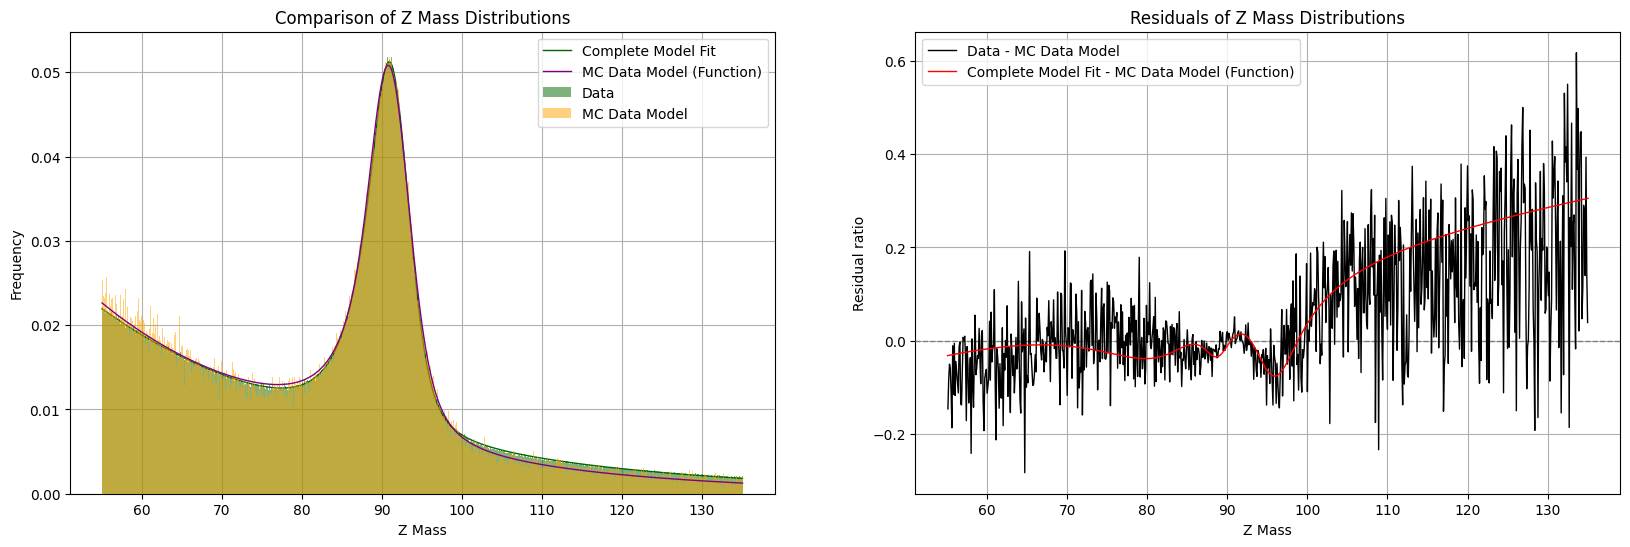

In [ ]:
bin_centers = (bins[:-1] + bins[1:]) / 2
data_bins = np.histogram(data_egamD / 1000, bins=bins, density=True)[0]
mc_sig_bins = np.histogram(data_egam1 / 1000, bins=bins, density=True)[0]
mc_bkg_bins = np.histogram(data_egam7 / 1000, bins=bins, density=True)[0]
mc_data_bins = mc_sig_bins * sig_strength + mc_bkg_bins * (1-sig_strength)

X = np.linspace(bins[0], bins[-1], 1000)
Y_data = curve_fitting.true_data_fit(X, *vals_egamD_full[0])
Y_mc_data = curve_fitting.breit_wigner_crystal_ball(X, *vals_egam1[0]) * sig_strength + curve_fitting.exponential_decay(X, *vals_egam7[0]) * (1-sig_strength)

fig, ax = plt.subplots(1, 2, figsize=(20, 6))
#plt.hist(data_egam1 / 1000, bins=bins, alpha=0.5, label="EGAM1", density=True, color="darkblue", zorder=2)
#plt.hist(data_egam7 / 1000, bins=bins, alpha=0.5, label="EGAM7", density=True, color="darkred", zorder=2)
#plt.hist(data_egamD / 1000, bins=bins, alpha=0.5, label="Data", density=True, color="darkgreen", zorder=2)

#plt.plot(X, curve_fitting.breit_wigner_crystal_ball(X, *vals_egam1[0]), color="darkblue", label="BW convolved with CB (Sig)", linewidth=1, zorder=10)
#plt.plot(X, curve_fitting.exponential_decay(X, *vals_egam7[0]), color="darkred", label="Exponential Decay (Bkg)", linewidth=1, zorder=10)
#plt.plot(X, data_fit_ratio(X, *vals_egamD_ratio), color="darkgreen", label="Fitted Data Model", linewidth=1, zorder=10)
ax[0].bar(bin_centers, data_bins, color="darkgreen", label="Data", width=(bins[1]-bins[0]), zorder=10, alpha=0.5)
ax[0].plot(X, Y_data, color="darkgreen", label="Complete Model Fit", linewidth=1, zorder=10)
ax[0].bar(bin_centers, mc_data_bins, color="orange", label="MC Data Model", width=(bins[1]-bins[0]), zorder=10, alpha=0.5)
ax[0].plot(X, Y_mc_data, color="purple", label="MC Data Model (Function)", linewidth=1, zorder=10)
ax[0].set_xlabel("Z Mass")
ax[0].set_ylabel("Frequency")
ax[0].set_title("Comparison of Z Mass Distributions")
ax[0].legend()
ax[0].grid()

ax[1].plot(bin_centers, (data_bins - mc_data_bins)/data_bins, color="black", label="Data - MC Data Model", linewidth=1, zorder=10)
ax[1].plot(X, (Y_data - Y_mc_data)/Y_data, color="red", label="Complete Model Fit - MC Data Model (Function)", linewidth=1, zorder=10)
ax[1].axhline(0, color="gray", linestyle="--", linewidth=1, zorder=5)
ax[1].set_xlabel("Z Mass")
ax[1].set_ylabel("Residual ratio")
ax[1].set_title("Residuals of Z Mass Distributions")
ax[1].legend()
ax[1].grid()


plt.show()

In [ ]:
Y_exp = curve_fitting.exponential_decay(X, vals_egamD_full[1], vals_egamD_full[-1])
Y_peak = curve_fitting.breit_wigner_crystal_ball(X, vals_egamD_full[0], vals_egamD_full[2], vals_egamD_full[3], vals_egamD_full[4], vals_egamD_full[5], vals_egamD_full[6])
exp_ratio = np.trapezoid(Y_exp, X)
peak_ratio = np.trapezoid(Y_peak, X)
plt.plot(X, Y_exp, color="orange", label="Exponential Decay Component", linewidth=1, zorder=10)
plt.plot(X, Y_peak, color="blue", label="Breit-Wigner convolved with Crystal Ball Component", linewidth=1, zorder=10)
print("Integral of Exponential Decay Component:", exp_ratio) 
print("Integral of Breit-Wigner convolved with Crystal Ball Component:", peak_ratio)

In [ ]:
vals_muon1, err_muon1, fval_muon1 = curve_fitting.fit_function(
    data_muon1 / 1000,
    bins,
    curve_fitting.breit_wigner_crystal_ball,
    initial_guess=[1.09716406, 91.1876, 2.98179821, 1.91401491, 1.16373524, 1.86966453],
    limits=bw_cb_limits,
)
vals_muonD_full, err_data, fval_data = curve_fitting.fit_function(
    data_muonD / 1000,
    bins,
    curve_fitting.true_data_fit,
    initial_guess=[1, 1, 91.1876, 2.4952, 2.5, 1.6, 1.5, 0.1]
    limits=data_fit_limits,
)

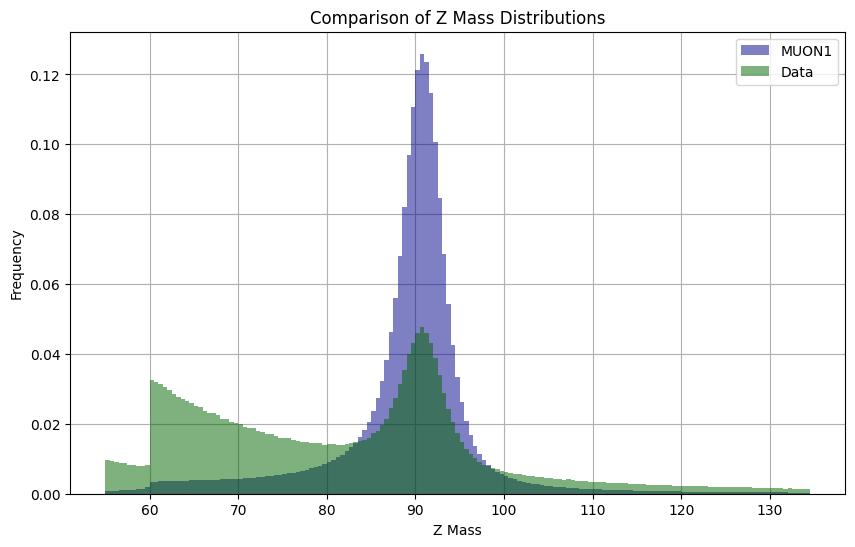

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(data_muon1 / 1000, bins=bins, alpha=0.5, label="MUON1", density=True, color="darkblue", zorder=2)
plt.hist(data_muonD / 1000, bins=bins, alpha=0.5, label="Data", density=True, color="darkgreen", zorder=2)
plt.plot(X, curve_fitting.breit_wigner_crystal_ball(X, *vals_muon1), color="darkblue", label="Breit-Wigner convolved with Crystal Ball (EGAM1)", linewidth=1, zorder=10)
plt.plot(X, curve_fitting.true_data_fit(X, *vals_muonD_full), color="darkgreen", label="Fitted True Data Model", linewidth=1, zorder=10)
plt.xlabel("Z Mass")
plt.ylabel("Frequency")
plt.title("Comparison of Z Mass Distributions")
plt.legend()
plt.grid()

In [ ]:

electron_events = np.array([218019944, 9964151, 16232916]) #Number of events in EGAM1, EGAM7, and DataEgamma respectively.
electron_e2_events = np.array([len(data_egam1), len(data_egam7), len(data_egamD)]) #Number of events with 2 electrons in EGAM1, EGAM7, and DataEgamma respectively.
muon_events = np.array([288835800, 57192146])
ratios = electron_e2_events / electron_events
ratios

array([0.38865768, 0.04348138, 0.43423406])

In [ ]:
num_z_found = len(data_egamD)*vals_egamD_ratio[0]
num_z_estimated = num_z_found/ratios[0]

print(f"Number of found Z events in data: {int(num_z_found)}")
print(f"Estimated number of Z events in data: {int(num_z_estimated)}")

Number of found Z events in data: 2940660
Estimated number of Z events in data: 7566196


In [ ]:
data = 36.1
cross_section = 1.981 * 1e6
electron_branch_ratio = 0.03363
expected = data * cross_section * electron_branch_ratio
expected

2405019.183